In [4]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns  
from scipy.stats import shapiro


main_dir = "../Data/ROI/Fig 3C 322_both_07_left_parahippoc_2p5_mask"

condition_map = {
    '02_rel_dist_stay': 'rel',
    '03_irrel_dist_stay': 'irrel'
}

def parse_file_name(file_name: str):
    m = re.match(r"(\d{2})_(\d)_\d{3}_.*", file_name)
    if m:
        return m.group(1), m.group(2)
    return None, None

def build_df_long(main_dir, condition_map):
    data = {}
    for root, _, files in os.walk(main_dir):
        condition = os.path.basename(root)
        if condition not in condition_map:
            continue
        for file in files:
            if not file.endswith(".txt"):
                continue
            fpath = os.path.join(root, file)
            pid, session = parse_file_name(file)
            if not (pid and session):
                continue
            try:
                with open(fpath, "r") as f:
                    val = float(f.read().strip())
                data.setdefault(session, {}).setdefault(condition, {})[pid] = val
            except Exception:
                continue

    if not data:
        raise RuntimeError("No data found. Check 'main_dir' and folder names.")

    rows = []
    for session in sorted(data.keys(), key=lambda x: int(x) if str(x).isdigit() else x):
        sdat = data[session]
        participants = set(k for d in sdat.values() for k in d.keys())
        for pid in participants:
            for cond, rel in condition_map.items():
                val = sdat.get(cond, {}).get(pid, np.nan)
                rows.append({
                    "Participant": str(pid),
                    "Session": int(session) if str(session).isdigit() else session,
                    "Relevance": rel,
                    "Value": val
                })
    df = pd.DataFrame(rows)
    df["Relevance"] = pd.Categorical(df["Relevance"], categories=["rel","irrel"], ordered=True)
    return df

def remove_outliers_vectorized(df):
    df = df.dropna(subset=["Value"]).copy()
    grp = df.groupby(["Session", "Relevance"], observed=True)
    m = grp["Value"].transform("mean")
    s = grp["Value"].transform("std")
    mask = (s.eq(0)) | (df["Value"].between(m - 3*s, m + 3*s))
    return df[mask].copy()

df_long = build_df_long(main_dir, condition_map)

# Report counts pre-clean
pre_counts = (df_long.dropna(subset=["Value"])
              .groupby(["Session","Relevance"], observed=True)
              .size().rename("N").reset_index())
print("\nCell counts BEFORE outlier removal:")
print(pre_counts)

# Clean: outliers
clean = remove_outliers_vectorized(df_long)

post_counts = (clean.groupby(["Session","Relevance"], observed=True)
                    .size().rename("N").reset_index())
print("\nCell counts AFTER outlier removal:")
print(post_counts)

# Aggregate duplicates: exactly one value per Participant×Session×Relevance
df_cell = (clean
           .groupby(["Participant","Session","Relevance"], observed=True, as_index=False)
           .agg(Value=("Value","mean")))

# ======= EXCLUDE participants with fewer than 2 sessions =======
sessions_per_pid = df_cell.groupby("Participant")["Session"].nunique()
keep_pids = sessions_per_pid[sessions_per_pid >= 2].index
df_cell = df_cell[df_cell["Participant"].isin(keep_pids)].copy()
print(f"\nParticipants after excluding <2 sessions: {len(keep_pids)}")

# Enforce balance: participants must have BOTH relevance levels in EACH session they contribute to.
wide = df_cell.pivot_table(index="Participant",
                           columns=["Session","Relevance"],
                           values="Value",
                           aggfunc="mean")

# Keep only participants with no missing cells across ALL observed Session×Relevance columns
wide_balanced = wide.dropna(axis=0).copy()
wide_balanced.index.name = 'Participant'  # crucial so 'Participant' becomes a column after reset_index()

# Robust reshape: MultiIndex columns -> long
df_anova = (
    wide_balanced
        .stack(level=[0, 1])           # stacks top level 'Session' and second level 'Relevance'
        .rename('Value')
        .reset_index()                 # -> columns: Participant, Session, Relevance, Value
)

# Clean dtypes and ordering
df_anova.columns = ['Participant', 'Session', 'Relevance', 'Value']
df_anova['Participant'] = df_anova['Participant'].astype(str)

session_levels = sorted(df_anova['Session'].unique())
df_anova['Session'] = pd.Categorical(df_anova['Session'], categories=session_levels, ordered=True)
df_anova['Relevance'] = pd.Categorical(df_anova['Relevance'], categories=['rel', 'irrel'], ordered=True)

# Run RM ANOVA (statsmodels)
from statsmodels.stats.anova import AnovaRM

aov = AnovaRM(
    data=df_anova,
    depvar='Value',
    subject='Participant',
    within=['Session', 'Relevance'],
    aggregate_func='mean'  # safeguard; there should be exactly 1 row per cell
).fit()

print(aov)

print("\nDone.")



Cell counts BEFORE outlier removal:
   Session Relevance   N
0        1       rel  23
1        1     irrel  23
2        2       rel  22
3        2     irrel  22

Cell counts AFTER outlier removal:
   Session Relevance   N
0        1       rel  23
1        1     irrel  23
2        2       rel  22
3        2     irrel  21

Participants after excluding <2 sessions: 22
                     Anova
                  F Value Num DF  Den DF Pr > F
-----------------------------------------------
Session            0.6035 1.0000 20.0000 0.4464
Relevance          0.6403 1.0000 20.0000 0.4330
Session:Relevance  1.7155 1.0000 20.0000 0.2051


Done.


/var/folders/2p/z_kqxw2d0m1264c9dxjbpm6h0000gp/T/ipykernel_55462/1984892460.py:100: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  wide = df_cell.pivot_table(index="Participant",
/var/folders/2p/z_kqxw2d0m1264c9dxjbpm6h0000gp/T/ipykernel_55462/1984892460.py:112: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  .stack(level=[0, 1])           # stacks top level 'Session' and second level 'Relevance'


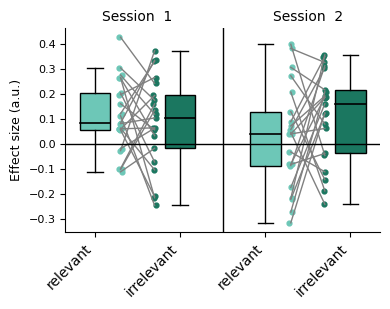

In [2]:
import matplotlib.pyplot as plt
import numpy as np

def plot_within_session_pairs_and_boxplots(
    df_anova,
    rel_color="#6DC7B7",
    irrel_color="#1B7760",
    line_color="gray",
    line_width=1.0,
    point_size=12,
    jitter=0.0,
    save_path=None,  
):
    d = df_anova.copy()
    d["Session"] = d["Session"].astype(str)
    d["Relevance"] = d["Relevance"].astype(str)

    sessions = sorted(d["Session"].unique(), key=lambda x: int(x) if x.isdigit() else x)
    if len(sessions) != 2 or set(d["Relevance"].unique()) != {"rel", "irrel"}:
        raise RuntimeError("Need exactly 2 sessions and relevance={'rel','irrel'}")

    base_pos = {sessions[0]: 0, sessions[1]: 1}
    offsets_box = {"rel": -0.25, "irrel": 0.25}
    offsets_scatter = {"rel": -0.10, "irrel": 0.10}
    colors = {"rel": rel_color, "irrel": irrel_color}

    fig, ax = plt.subplots(figsize=(4, 3.2))

    # Lines + points connecting rel ↔ irrel within each session
    for sess in sessions:
        sub = d[d["Session"] == sess]
        pvt = sub.pivot_table(index="Participant", columns="Relevance", values="Value", aggfunc="mean").dropna()
        x_rel = base_pos[sess] + offsets_scatter["rel"]
        x_irr = base_pos[sess] + offsets_scatter["irrel"]
        for _, row in pvt.iterrows():
            j_rel = (np.random.rand()*2-1)*jitter if jitter else 0.0
            j_irr = (np.random.rand()*2-1)*jitter if jitter else 0.0
            ax.plot([x_rel, x_irr], [row["rel"], row["irrel"]], color=line_color, linewidth=line_width)
            ax.scatter(x_rel + j_rel, row["rel"], color=colors["rel"], s=point_size)
            ax.scatter(x_irr + j_irr, row["irrel"], color=colors["irrel"], s=point_size)

    # Boxplots for each Session×Relevance cell
    box_data, box_positions = [], []
    for sess in sessions:
        for rel in ["rel", "irrel"]:
            box_data.append(d[(d["Session"] == sess) & (d["Relevance"] == rel)]["Value"].dropna().values)
            box_positions.append(base_pos[sess] + offsets_box[rel])

    bp = ax.boxplot(
        box_data,
        positions=box_positions,
        widths=0.18,
        patch_artist=True,
        manage_ticks=False,
        showfliers=False,
        medianprops=dict(color="black", linewidth=1.2),
        whiskerprops=dict(color="black", linewidth=1.0),
        capprops=dict(color="black", linewidth=1.0),
        boxprops=dict(edgecolor="black", linewidth=1.0)
    )

    box_colors = [rel_color, irrel_color, rel_color, irrel_color]  # order: S1 rel, S1 irrel, S2 rel, S2 irrel
    for patch, c in zip(bp["boxes"], box_colors):
        patch.set_facecolor(c)
        patch.set_alpha(0.6)

    for spine in ax.spines.values():
        spine.set_color("black")
    ax.set_ylabel("Effect size (a.u.)", fontsize=9)
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(False)
    ax.axhline(0, color="black", linewidth=1)


    # X-axis labels under each box, session headers, and separator
    xtick_positions = [
        base_pos[sessions[0]] + offsets_box['rel'],
        base_pos[sessions[0]] + offsets_box['irrel'],
        base_pos[sessions[1]] + offsets_box['rel'],
        base_pos[sessions[1]] + offsets_box['irrel'],
    ]
    ax.set_xticks(xtick_positions)
    ax.set_xticklabels(['relevant', 'irrelevant', 'relevant', 'irrelevant'], rotation=45, ha='right', va='top', fontsize=10)

    sep_x = 0.5
    ax.axvline(sep_x, color='black', linewidth=1)
    ax.text(base_pos[sessions[0]], 1.02, f"Session  {sessions[0]}", ha='center', va='bottom', fontsize=10, transform=ax.get_xaxis_transform())
    ax.text(base_pos[sessions[1]], 1.02, f"Session  {sessions[1]}", ha='center', va='bottom', fontsize=10, transform=ax.get_xaxis_transform())
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)   
    ax.tick_params(top=False, right=False)
    plt.tight_layout()

    if save_path:
        # EPS prefers no transparency; remove alpha to keep vector shapes
        for patch in bp['boxes']:
            patch.set_alpha(1.0)
        for coll in ax.collections:
            coll.set_alpha(1.0)
        

    plt.show()
    return fig, ax

fig, ax = plot_within_session_pairs_and_boxplots(df_anova, jitter=0.01, save_path="/Users/garvert_UW/Dropbox (University of Wuerzburg)/DropboxFiles/Privat/Projects/ManyMaps/Paper/Figure 3/figure3.eps")
